# Breast Cancer Dataset Analysis

# 1. Loading the Dataset
I loaded the Breast Cancer dataset using scikit-learn. It contains 569 samples, 30 features and two classes. I separated the features (X) and target labels (y).



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

In [2]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

X = cancer.data
y = cancer.target

df = pd.DataFrame(X, columns=cancer.feature_names)
df["target"] = y

X_df = pd.DataFrame(X, columns=cancer.feature_names)
print("X shape:", X.shape)
print("df shape:", df.shape)
print("X_df shape:", X_df.shape)

X shape: (569, 30)
df shape: (569, 31)
X_df shape: (569, 30)


In [3]:
from IPython.display import display

In [4]:
print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst five rows:")
display(df.head())

print("\nFeature names:")
print(cancer.feature_names)

print("\nTarget names:")
print(cancer.target_names)

print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())

Dataset shape: (569, 30)
Target shape: (569,)

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Feature names:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']

Target names:
['malignant' 'benign']

Class distribution:
0    212
1    357
Name: count, dtype: int64


## 2. Data Quality Checks
I checked the dataset for missing values, duplicates and potential outliers. I also checked the feature data types. I kept the original observations without removing outliers.

In [5]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Missing values per column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Total missing values:
0

Duplicate rows:
0

Data types:
mean

In [6]:
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Total missing values: 0
Duplicate rows: 0


In [7]:
X_df = pd.DataFrame(X, columns=cancer.feature_names)

In [8]:
Q1 = X_df.quantile(0.25)
Q3 = X_df.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = ((X_df < lower_bound) | (X_df > upper_bound)).sum()

print(outlier_counts.sort_values(ascending=False))

area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
worst symmetry             23
concavity error            22
texture error              20
concave points error       19
mean concavity             18
worst radius               17
worst compactness          16
mean compactness           16
mean symmetry              15
mean fractal dimension     15
worst perimeter            15
mean radius                14
mean perimeter             13
worst concavity            12
mean concave points        10
mean texture                7
worst smoothness            7
mean smoothness             6
worst texture               5
worst concave points        0
dtype: int64


In [9]:
numeric_features = X_df.select_dtypes(include=np.number).shape[1]
categorical_features = X_df.select_dtypes(include="object").shape[1]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: 30
Categorical features: 0


## 3. Exploratory Data Analysis (EDA)
I calculated descriptive statistics and examined the class distribution. I also created a correlation heatmap and boxplots to understand the relationships and differences between features.

In [10]:
summary_stats = X_df.describe().T

summary_stats = summary_stats[
    ["mean", "50%", "min", "max", "std", "25%", "75%"]
]

summary_stats = summary_stats.rename(columns={
    "50%": "median",
    "25%": "Q1",
    "75%": "Q3"
})

display(summary_stats)

,mean,median,min,max,std,Q1,Q3
mean radius,14.127292,13.370000,6.981000,28.11000,3.524049,11.700000,15.780000
mean texture,19.289649,18.840000,9.710000,39.28000,4.301036,16.170000,21.800000
mean perimeter,91.969033,86.240000,43.790000,188.50000,24.298981,75.170000,104.100000
mean area,654.889104,551.100000,143.500000,2501.00000,351.914129,420.300000,782.700000
mean smoothness,0.096360,0.095870,0.052630,0.16340,0.014064,0.086370,0.105300
mean compactness,0.104341,0.092630,0.019380,0.34540,0.052813,0.064920,0.130400
mean concavity,0.088799,0.061540,0.000000,0.42680,0.079720,0.029560,0.130700
mean concave points,0.048919,0.033500,0.000000,0.20120,0.038803,0.020310,0.074000
mean symmetry,0.181162,0.179200,0.106000,0.30400,0.027414,0.161900,0.195700
mean fractal dimension,0.062798,0.061540,0.049960,0.09744,0.007060,0.057700,0.066120


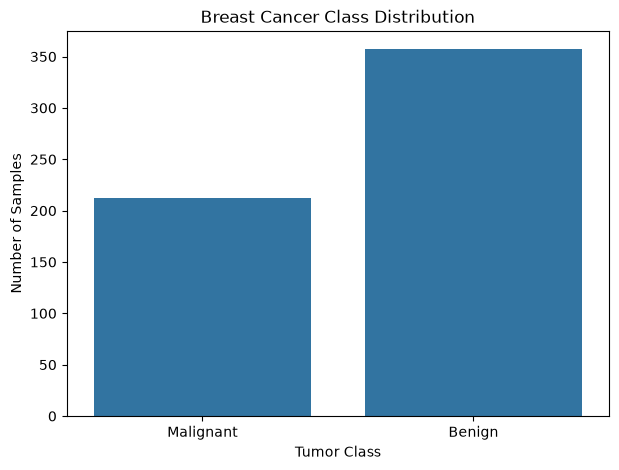

In [11]:
class_counts = pd.Series(y).value_counts().sort_index()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=["Malignant", "Benign"],
    y=class_counts.values
)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Tumor Class")
plt.ylabel("Number of Samples")
plt.show()

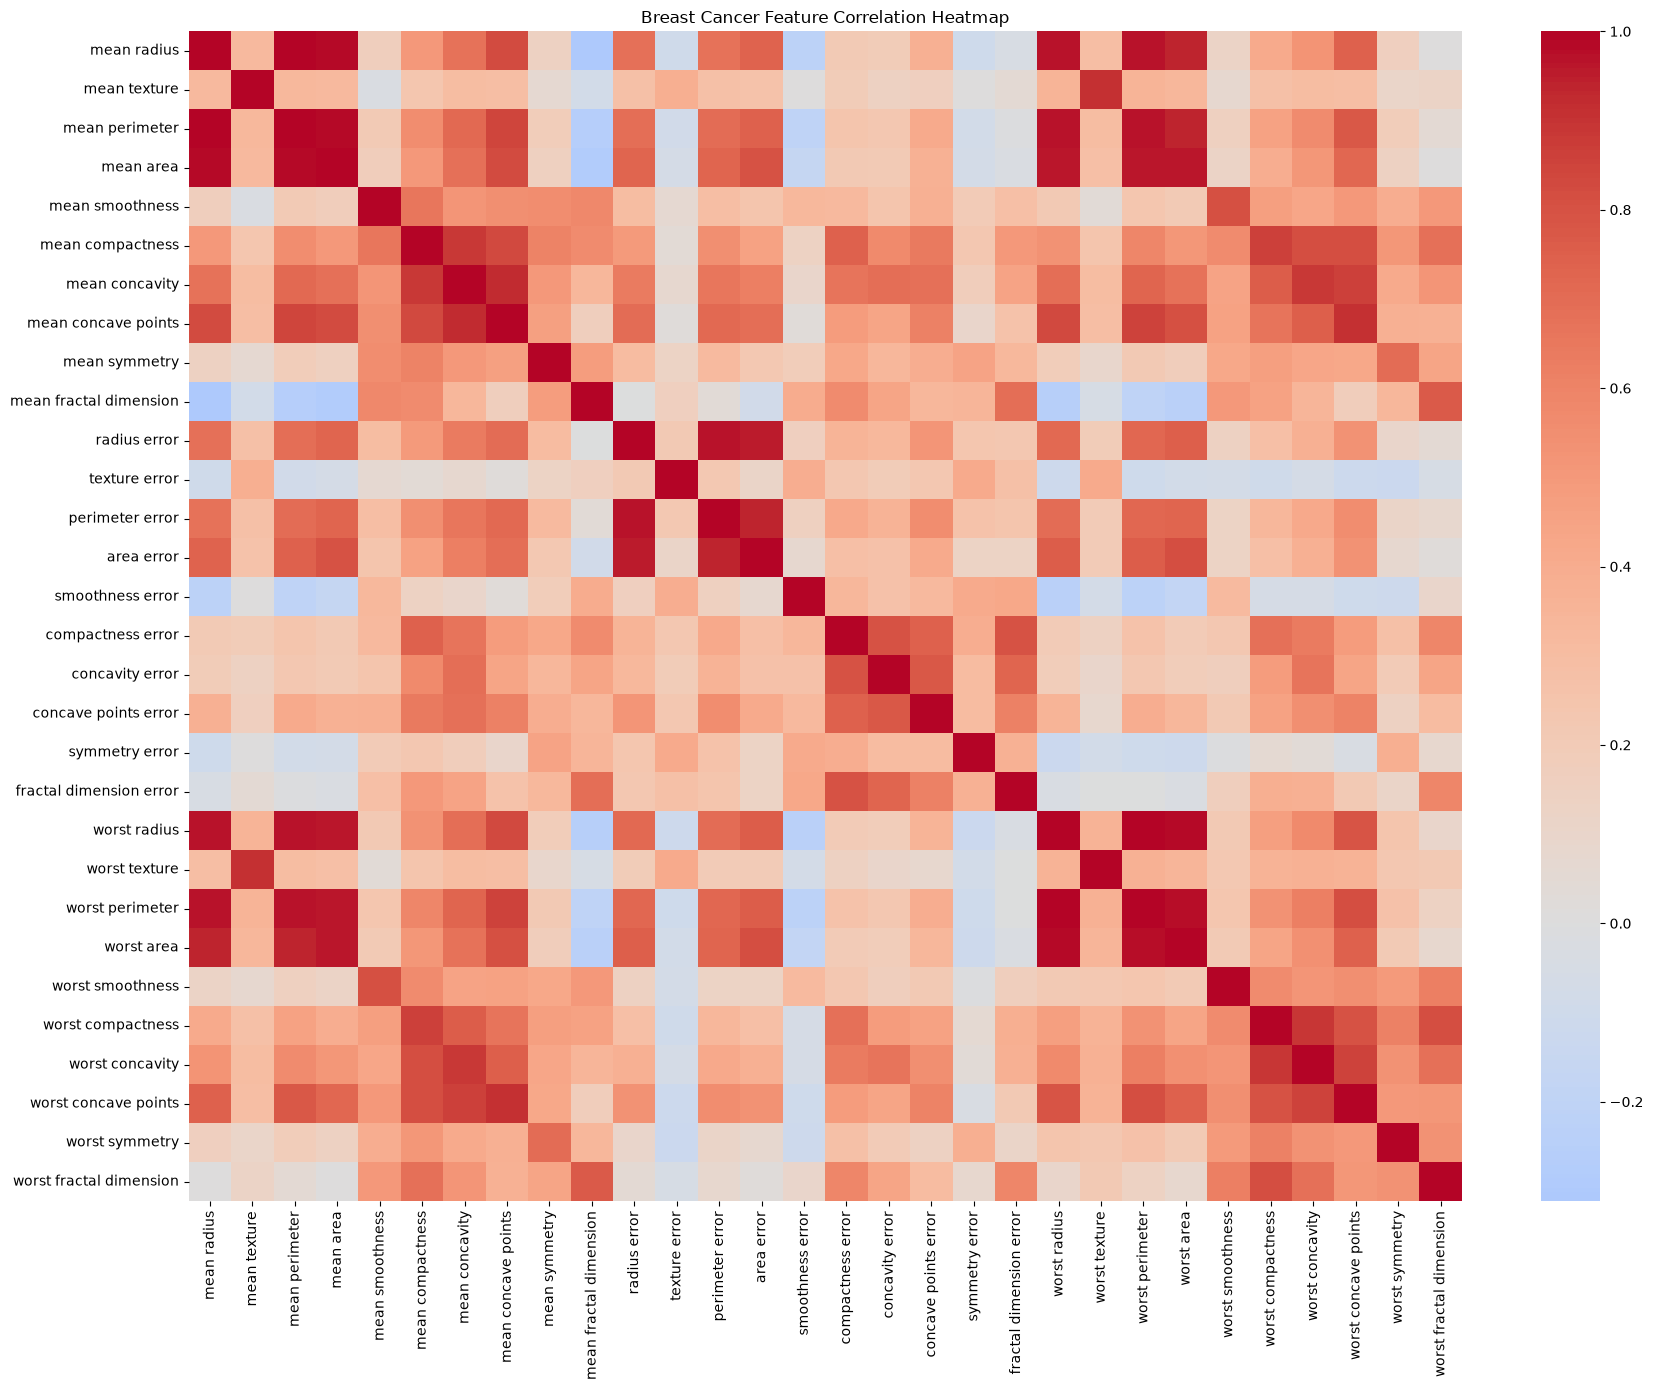

In [12]:
correlation_matrix = X_df.corr(method="pearson")

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Breast Cancer Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [13]:
correlation_pairs = correlation_matrix.abs().where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
).stack()

top_3_correlations = correlation_pairs.sort_values(
    ascending=False
).head(3)

print("Top 3 feature correlation pairs:")
print(top_3_correlations)

Top 3 feature correlation pairs:
mean radius   mean perimeter     0.997855
worst radius  worst perimeter    0.993708
mean radius   mean area          0.987357
dtype: float64


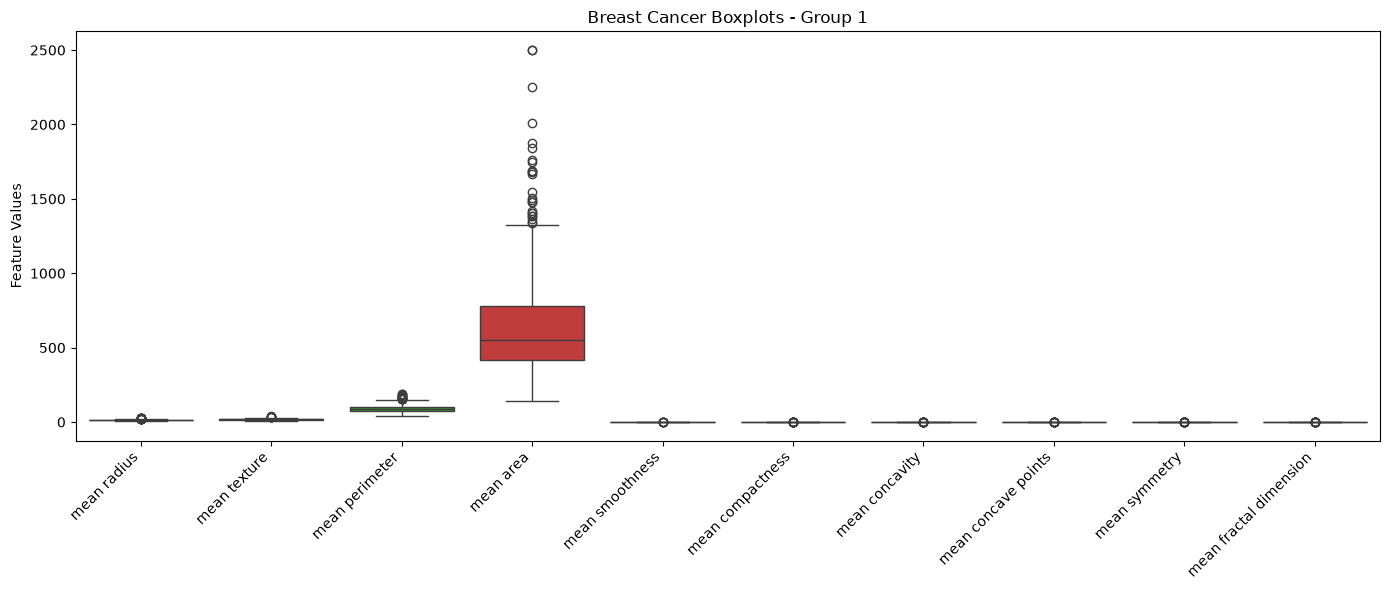

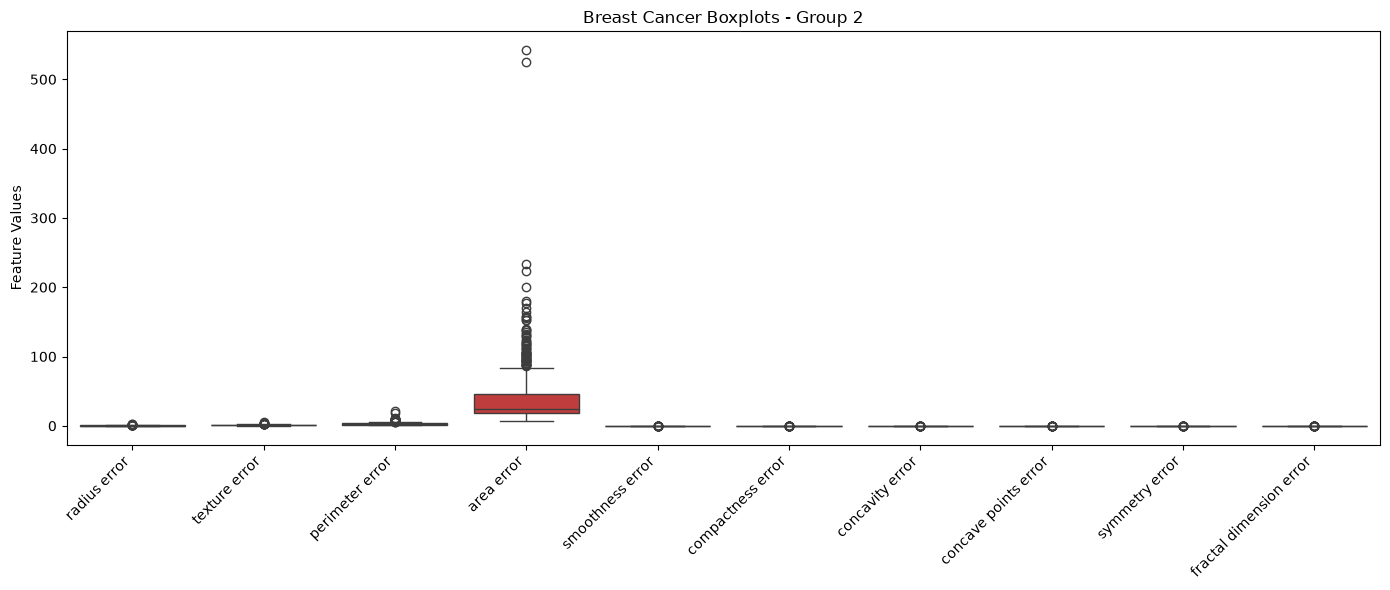

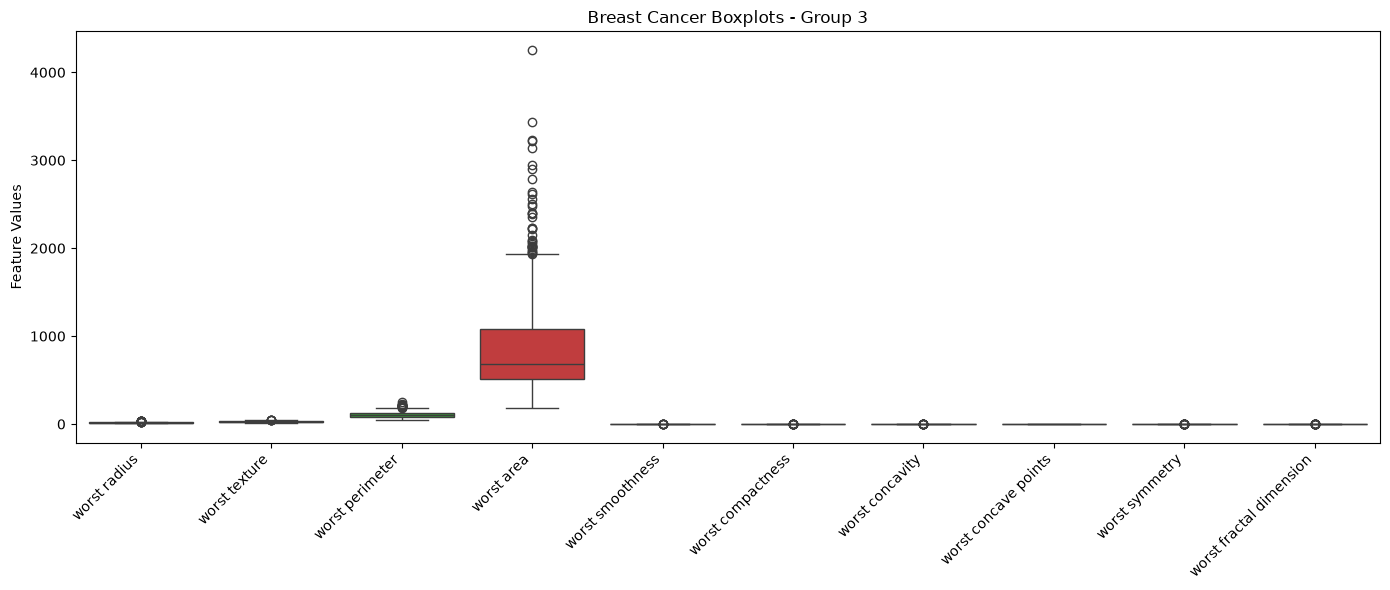

In [14]:

features = X_df.columns

for i in range(3):
    start = i * 10
    end = start + 10

    plt.figure(figsize=(14, 6))

    sns.boxplot(data=X_df[features[start:end]])

    plt.title(f"Breast Cancer Boxplots - Group {i + 1}")
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Feature Values")
    plt.tight_layout()
    plt.show()

## 4. Splitting the Datasets
I divided the dataset into approximately 70% training, 10% validation and 20% testing. I used three seeds: 42, 52 and 62. The test set stayed the same for all experiments.

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
# Target variable as a Pandas Series
y_series = pd.Series(y, index=X_df.index)

# Split data into training-validation and test sets
train_val_idx, test_idx = train_test_split(
    X_df.index,
    test_size=0.20,
    random_state=42,
    stratify=y_series
)

print("Training + Validation:", len(train_val_idx))
print("Test:", len(test_idx))

Training + Validation: 455
Test: 114


In [17]:
seeds = [42, 52, 62]

splits = {}

for seed in seeds:
    train_idx, val_idx = train_test_split(
        train_val_idx,
        test_size=0.125,
        random_state=seed,
        stratify=y_series.loc[train_val_idx]
    )

    splits[seed] = {
        "train_idx": train_idx,
        "val_idx": val_idx,
        "test_idx": test_idx
    }

    print(f"\nSeed: {seed}")
    print("Training:", len(train_idx))
    print("Validation:", len(val_idx))
    print("Test:", len(test_idx))


Seed: 42
Training: 398
Validation: 57
Test: 114

Seed: 52
Training: 398
Validation: 57
Test: 114

Seed: 62
Training: 398
Validation: 57
Test: 114


In [18]:
for seed, split in splits.items():
    train_idx = split["train_idx"]
    val_idx = split["val_idx"]
    test_idx = split["test_idx"]

    print(f"\n--- Seed {seed} ---")

    print("Total samples:",
          len(train_idx) + len(val_idx) + len(test_idx))

    print("Train-Validation overlap:",
          len(set(train_idx) & set(val_idx)))

    print("Train-Test overlap:",
          len(set(train_idx) & set(test_idx)))

    print("Validation-Test overlap:",
          len(set(val_idx) & set(test_idx)))

    print("Malignant/Benign distribution:")
    print("Train:\n", y_series.loc[train_idx].value_counts().sort_index())
    print("Validation:\n", y_series.loc[val_idx].value_counts().sort_index())
    print("Test:\n", y_series.loc[test_idx].value_counts().sort_index())


--- Seed 42 ---
Total samples: 569
Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0
Malignant/Benign distribution:
Train:
 0    149
1    249
Name: count, dtype: int64
Validation:
 0    21
1    36
Name: count, dtype: int64
Test:
 0    42
1    72
Name: count, dtype: int64

--- Seed 52 ---
Total samples: 569
Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0
Malignant/Benign distribution:
Train:
 0    149
1    249
Name: count, dtype: int64
Validation:
 0    21
1    36
Name: count, dtype: int64
Test:
 0    42
1    72
Name: count, dtype: int64

--- Seed 62 ---
Total samples: 569
Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0
Malignant/Benign distribution:
Train:
 0    149
1    249
Name: count, dtype: int64
Validation:
 0    21
1    36
Name: count, dtype: int64
Test:
 0    42
1    72
Name: count, dtype: int64


Seed	Split	Samples	Percentage	Malignant	Benign
42	Train	398	69.95%	149	249
42	Validation	57	10.02%	21	36
42	Test	114	20.04%	42	72
52	Train	398	69.95%	149	249
52	Validation	57	10.02%	21	36
52	Test	114	20.04%	42	72
62	Train	398	69.95%	149	249
62	Validation	57	10.02%	21	36
62	Test	114	20.04%	42	72

In [19]:
test_42 = set(splits[42]["test_idx"])
test_52 = set(splits[52]["test_idx"])
test_62 = set(splits[62]["test_idx"])

print("42 vs 52:", test_42 == test_52)
print("42 vs 62:", test_42 == test_62)
print("52 vs 62:", test_52 == test_62)

42 vs 52: True
42 vs 62: True
52 vs 62: True


## 5. Data Preprocessing and Scaling
I used StandardScaler to scale the feature values. I fitted the scaler only on training data to prevent data leakage. Then I transformed the validation and test data using the training-fitted scaler.

In [20]:
from sklearn.preprocessing import StandardScaler

In [21]:
scalers = {}
scaled_data = {}

for seed in seeds:

    train_idx = splits[seed]["train_idx"]
    val_idx = splits[seed]["val_idx"]
    test_idx = splits[seed]["test_idx"]

    # Get data
    X_train = X_df.loc[train_idx]
    X_val = X_df.loc[val_idx]
    X_test = X_df.loc[test_idx]

    # Create and fit scaler using training data only
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)

    # Transform validation and test data
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    # Save scaler and transformed data
    scalers[seed] = scaler

    scaled_data[seed] = {
        "X_train_scaled": X_train_scaled,
        "X_val_scaled": X_val_scaled,
        "X_test_scaled": X_test_scaled
    }

    print(f"\nSeed {seed}")
    print("Train shape:", X_train_scaled.shape)
    print("Validation shape:", X_val_scaled.shape)
    print("Test shape:", X_test_scaled.shape)


Seed 42
Train shape: (398, 30)
Validation shape: (57, 30)
Test shape: (114, 30)

Seed 52
Train shape: (398, 30)
Validation shape: (57, 30)
Test shape: (114, 30)

Seed 62
Train shape: (398, 30)
Validation shape: (57, 30)
Test shape: (114, 30)


In [22]:
print("Before Standardization:")
display(X_df.loc[splits[42]["train_idx"]].head())

print("After Standardization:")
display(
    pd.DataFrame(
        scaled_data[42]["X_train_scaled"],
        columns=X_df.columns
    ).head()
)

Before Standardization:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.08451,0.10140,0.06830,0.03099,0.1781,0.06249,...,13.46,23.07,88.13,551.3,0.1050,0.2158,0.19040,0.07625,0.2685,0.07764
390,10.26,12.22,65.75,321.6,0.09996,0.07542,0.01923,0.01968,0.1800,0.06569,...,11.38,15.65,73.23,394.5,0.1343,0.1650,0.08615,0.06696,0.2937,0.07722
420,11.57,19.04,74.20,409.7,0.08546,0.07722,0.05485,0.01428,0.2031,0.06267,...,13.07,26.98,86.43,520.5,0.1249,0.1937,0.25600,0.06664,0.3035,0.08284
356,13.05,18.59,85.09,512.0,0.10820,0.13040,0.09603,0.05603,0.2035,0.06501,...,14.19,24.85,94.22,591.2,0.1343,0.2658,0.25730,0.12580,0.3113,0.08317
446,17.75,28.03,117.30,981.6,0.09997,0.13140,0.16980,0.08293,0.1713,0.05916,...,21.53,38.54,145.40,1437.0,0.1401,0.3762,0.63990,0.19700,0.2972,0.09075


After Standardization:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,-0.464835,0.176821,-0.467521,-0.518737,-0.883771,-0.073305,-0.280632,-0.466742,-0.076775,-0.069315,...,-0.573411,-0.379056,-0.561075,-0.578285,-1.226438,-0.259443,-0.416465,-0.584935,-0.339632,-0.358158
1,-1.084133,-1.553003,-1.065325,-0.944480,0.250510,-0.553959,-0.868776,-0.752546,-0.009649,0.375173,...,-1.001136,-1.547363,-1.000394,-0.854885,0.069897,-0.573037,-0.892843,-0.723620,0.046080,-0.381146
2,-0.715369,-0.014881,-0.721221,-0.693926,-0.814026,-0.520657,-0.441841,-0.889004,0.806456,-0.044313,...,-0.653609,0.236588,-0.611199,-0.632617,-0.345992,-0.395869,-0.116701,-0.728397,0.196078,-0.073535
3,-0.298750,-0.116370,-0.277754,-0.402988,0.855460,0.463223,0.051734,0.166020,0.820588,0.280719,...,-0.423295,-0.098788,-0.381515,-0.507900,0.069897,0.049213,-0.110760,0.154767,0.315465,-0.055472
4,1.024295,2.012644,1.033914,0.932543,0.251244,0.481724,0.935926,0.845785,-0.317013,-0.531861,...,1.086082,2.056753,1.127502,0.984118,0.326509,0.730725,1.637560,1.217669,0.099650,0.359420


In [23]:
for seed in seeds:

    train_scaled_df = pd.DataFrame(
        scaled_data[seed]["X_train_scaled"],
        columns=X_df.columns
    )

    print(f"\n--- Seed {seed} ---")

    print("Mean:")
    print(train_scaled_df.mean().round(4))

    print("\nStandard Deviation:")
    print(train_scaled_df.std(ddof=0).round(4))


--- Seed 42 ---
Mean:
mean radius               -0.0
mean texture              -0.0
mean perimeter             0.0
mean area                  0.0
mean smoothness            0.0
mean compactness           0.0
mean concavity             0.0
mean concave points        0.0
mean symmetry              0.0
mean fractal dimension     0.0
radius error              -0.0
texture error              0.0
perimeter error           -0.0
area error                -0.0
smoothness error           0.0
compactness error          0.0
concavity error           -0.0
concave points error      -0.0
symmetry error             0.0
fractal dimension error    0.0
worst radius              -0.0
worst texture              0.0
worst perimeter            0.0
worst area                -0.0
worst smoothness          -0.0
worst compactness          0.0
worst concavity           -0.0
worst concave points      -0.0
worst symmetry             0.0
worst fractal dimension    0.0
dtype: float64

Standard Deviation:
mean radius

In [24]:
for seed in seeds:
    train_scaled_df = pd.DataFrame(
        scaled_data[seed]["X_train_scaled"],
        columns=X_df.columns
    )

    print(f"\nSeed {seed}")
    print("Mean absolute maximum:",
          train_scaled_df.mean().abs().max())
    print("Std minimum:",
          train_scaled_df.std(ddof=0).min())
    print("Std maximum:",
          train_scaled_df.std(ddof=0).max())


Seed 42
Mean absolute maximum: 1.4773218940740776e-15
Std minimum: 0.9999999999999998
Std maximum: 1.0

Seed 52
Mean absolute maximum: 1.2608562993230422e-15
Std minimum: 0.9999999999999997
Std maximum: 1.0

Seed 62
Mean absolute maximum: 1.1515076999127252e-15
Std minimum: 0.9999999999999998
Std maximum: 1.0


## 6. Preparing the Two Data Representations
I used two data representations: unscaled and scaled.
Unscaled data contains the original feature values, while scaled
data contains the same features transformed by StandardScaler.
Both representations use the same training and validation samples.

## 7. Training the Classification Models
In this section, I trained three classification algorithms: Decision Tree, KNN and Gaussian Naive Bayes.

For Decision Tree, I tested five different depths: 2, 3, 5, 10 and None. For KNN, I used five neighbour values: 1, 3, 5, 7 and 11. Gaussian Naive Bayes was used with default parameters.

I trained the models using both scaled and unscaled data with three different seeds: 42, 52 and 62.

In total, I performed 66 classification experiments for the Breast Cancer dataset. I used training data to train the models and validation data to evaluate their performance.

In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [26]:
results = []
trained_models = {}

for seed in seeds:

    train_idx = splits[seed]["train_idx"]
    val_idx = splits[seed]["val_idx"]

    # Original (unscaled) data
    X_train_original = X_df.loc[train_idx]
    X_val_original = X_df.loc[val_idx]

    # Scaled data
    X_train_scaled = pd.DataFrame(
        scaled_data[seed]["X_train_scaled"],
        columns=X_df.columns,
        index=train_idx
    )

    X_val_scaled = pd.DataFrame(
        scaled_data[seed]["X_val_scaled"],
        columns=X_df.columns,
        index=val_idx
    )

    y_train = y_series.loc[train_idx]
    y_val = y_series.loc[val_idx]

    representations = {
        "unscaled": (X_train_original, X_val_original),
        "scaled": (X_train_scaled, X_val_scaled)
    }

    for representation, (X_train, X_val) in representations.items():

        models = []

        # Decision Tree
        for depth in [2, 3, 5, 10, None]:
            models.append((
                f"DecisionTree_depth_{depth}",
                DecisionTreeClassifier(
                    max_depth=depth,
                    random_state=seed
                )
            ))

        # KNN
        for k in [1, 3, 5, 7, 11]:
            models.append((
                f"KNN_k_{k}",
                KNeighborsClassifier(
                    n_neighbors=k,
                    weights="uniform",
                    metric="euclidean"
                )
            ))

        # Gaussian Naive Bayes
        models.append((
            "GaussianNB",
            GaussianNB()
        ))

        for model_name, model in models:

            model.fit(X_train, y_train)
            
            
            if seed == 42:
               
               trained_models[(seed, representation, model_name)] = model

            train_pred = model.predict(X_train)
            val_pred = model.predict(X_val)

            # Probability of malignant class (original label 0)
            malignant_index = list(model.classes_).index(0)
            val_proba = model.predict_proba(X_val)[:, malignant_index]

            # Convert malignant class to positive class
            y_val_binary = (y_val == 0).astype(int)

            results.append({
                "seed": seed,
                "representation": representation,
                "model": model_name,

                "train_accuracy": accuracy_score(
                    y_train, train_pred
                ),

                "train_macro_f1": f1_score(
                    y_train, train_pred,
                    average="macro",
                    zero_division=0
                ),

                "accuracy": accuracy_score(
                    y_val, val_pred
                ),

                "precision_macro": precision_score(
                    y_val, val_pred,
                    average="macro",
                    zero_division=0
                ),

                "recall_macro": recall_score(
                    y_val, val_pred,
                    average="macro",
                    zero_division=0
                ),

                "f1_macro": f1_score(
                    y_val, val_pred,
                    average="macro",
                    zero_division=0
                ),

                "roc_auc": roc_auc_score(
                    y_val_binary, val_proba
                )
            })

cancer_results = pd.DataFrame(results)

print("Total model runs:", len(cancer_results))
display(cancer_results.head(10))

Total model runs: 66


,seed,representation,model,train_accuracy,train_macro_f1,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
0,42,unscaled,DecisionTree_depth_2,0.954774,0.951595,0.894737,0.894737,0.876984,0.884459,0.875661
1,42,unscaled,DecisionTree_depth_3,0.972362,0.970031,0.894737,0.894737,0.876984,0.884459,0.919312
2,42,unscaled,DecisionTree_depth_5,0.997487,0.997314,0.912281,0.909459,0.900794,0.904778,0.921296
3,42,unscaled,DecisionTree_depth_10,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603
4,42,unscaled,DecisionTree_depth_None,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603
5,42,unscaled,KNN_k_1,1.000000,1.000000,0.859649,0.855263,0.839286,0.845946,0.839286
6,42,unscaled,KNN_k_3,0.959799,0.956730,0.877193,0.880342,0.853175,0.863590,0.916005
7,42,unscaled,KNN_k_5,0.952261,0.948690,0.894737,0.894737,0.876984,0.884459,0.929894
8,42,unscaled,KNN_k_7,0.949749,0.945912,0.912281,0.909459,0.900794,0.904778,0.951058
9,42,unscaled,KNN_k_11,0.947236,0.943125,0.929825,0.934211,0.914683,0.922973,0.955026


## 8. Measuring Validation Performance
We evaluated the models using accuracy, macro precision, macro recall, macro F1-score and ROC-AUC. We calculated the mean and standard deviation across three seeds to compare their performance. The best model was scaled KNN with k=7, which achieved a mean validation macro F1-score of 0.9677.

In [27]:
metrics = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "roc_auc"
]

summary = cancer_results.groupby(
    ["representation", "model"]
)[metrics].agg(["mean", "std"])

summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary.columns
]

summary = summary.reset_index()

summary = summary.sort_values(
    by=["f1_macro_mean", "accuracy_mean", "f1_macro_std"],
    ascending=[False, False, True]
)

display(summary)


,representation,model,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std,roc_auc_mean,roc_auc_std
10,scaled,KNN_k_7,0.970760,0.026799,0.978408,0.019661,0.960317,0.036370,0.967675,0.029718,0.978175,0.019384
7,scaled,KNN_k_11,0.964912,0.035088,0.974561,0.025012,0.952381,0.047619,0.960846,0.039478,0.994489,0.004785
8,scaled,KNN_k_3,0.959064,0.020258,0.969854,0.014404,0.944444,0.027493,0.954677,0.022757,0.979277,0.016151
9,scaled,KNN_k_5,0.959064,0.020258,0.969854,0.014404,0.944444,0.027493,0.954677,0.022757,0.979497,0.017386
6,scaled,KNN_k_1,0.941520,0.020258,0.940964,0.028337,0.933862,0.016038,0.936898,0.021295,0.933862,0.016038
16,unscaled,GaussianNB,0.941520,0.020258,0.938445,0.016375,0.937169,0.030759,0.936854,0.022646,0.979718,0.012572
5,scaled,GaussianNB,0.929825,0.017544,0.923854,0.014035,0.927910,0.028912,0.924770,0.020075,0.975970,0.014941
0,scaled,DecisionTree_depth_10,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
4,scaled,DecisionTree_depth_None,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
11,unscaled,DecisionTree_depth_10,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952


In [28]:
summary.to_csv("bc_classifier_summary.csv", index=False)
cancer_results.to_csv("bc_classifier_runs.csv", index=False)

print("CSV files have been saved succesfully")

CSV files have been saved succesfully


## 9. Final Test Evaluation
### 9.1 Best Model Selection
I evaluated the selected KNN model with k=7 on the fixed test set. It achieved 97.37% accuracy and a macro F1-score of 0.9713. I also examined the confusion matrix and ROC curve.


In [29]:
best_config = summary.iloc[0]

print("Best Model:", best_config["model"])
print("Representation:", best_config["representation"])
print("Mean Validation F1:", best_config["f1_macro_mean"])

Best Model: KNN_k_7
Representation: scaled
Mean Validation F1: 0.9676749826749828


In [30]:
from sklearn.neighbors import KNeighborsClassifier

final_model = trained_models[(42, "scaled", "KNN_k_7")]

print("Previously trained model loaded successfully!")

Previously trained model loaded successfully!


In [31]:
X_test_final = scaled_data[42]["X_test_scaled"]
y_test_final = y_series.loc[splits[42]["test_idx"]]

y_pred = final_model.predict(X_test_final)

print("Test predictions completed!")
print("Number of predictions:", len(y_pred))

Test predictions completed!
Number of predictions: 114


c:\Users\PC\Desktop\Machine_Learning_Project\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate classification metrics
test_accuracy = accuracy_score(y_test_final, y_pred)

test_precision = precision_score(
    y_test_final, y_pred, average="macro", zero_division=0
)

test_recall = recall_score(
    y_test_final, y_pred, average="macro", zero_division=0
)

test_f1 = f1_score(
    y_test_final, y_pred, average="macro", zero_division=0
)

# Malignant (class 0) is the positive class
y_test_binary = (y_test_final == 0).astype(int)

malignant_index = list(final_model.classes_).index(0)

y_test_proba = final_model.predict_proba(X_test_final)[:, malignant_index]

test_roc_auc = roc_auc_score(y_test_binary, y_test_proba)

# Display results
print("TEST SET RESULTS")
print("-------------------------")
print(f"Accuracy:        {test_accuracy:.4f}")
print(f"Precision Macro: {test_precision:.4f}")
print(f"Recall Macro:    {test_recall:.4f}")
print(f"F1 Macro:        {test_f1:.4f}")
print(f"ROC-AUC:         {test_roc_auc:.4f}")

TEST SET RESULTS
-------------------------
Accuracy:        0.9737
Precision Macro: 0.9800
Recall Macro:    0.9643
F1 Macro:        0.9713
ROC-AUC:         0.9888


c:\Users\PC\Desktop\Machine_Learning_Project\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


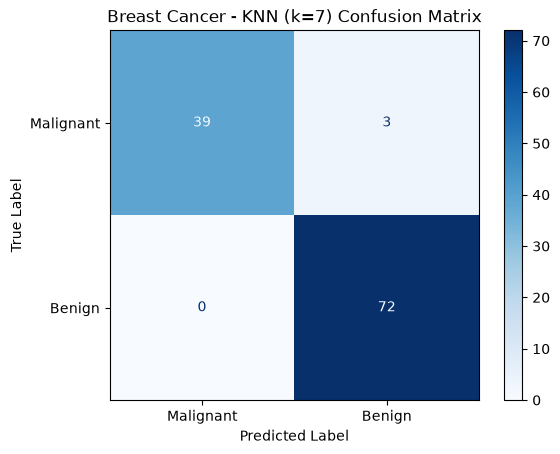

[[39  3]
 [ 0 72]]


In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(
    y_test_final,
    y_pred,
    labels=[0, 1]
)

# Display confusion matrix
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("Breast Cancer - KNN (k=7) Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

print(cm)

In [34]:
TP = 39
FP = 0
FN = 3

malignant_precision = TP / (TP + FP)
malignant_recall = TP / (TP + FN)

malignant_f1 = (
    2 * malignant_precision * malignant_recall
    / (malignant_precision + malignant_recall)
)

print("Malignant Precision:", malignant_precision)
print("Malignant Recall:", malignant_recall)
print("Malignant F1:", malignant_f1)

Malignant Precision: 1.0
Malignant Recall: 0.9285714285714286
Malignant F1: 0.962962962962963


In [35]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test_final,
    y_pred,
    labels=[0, 1],
    target_names=["Malignant", "Benign"],
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

   Malignant       1.00      0.93      0.96        42
      Benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



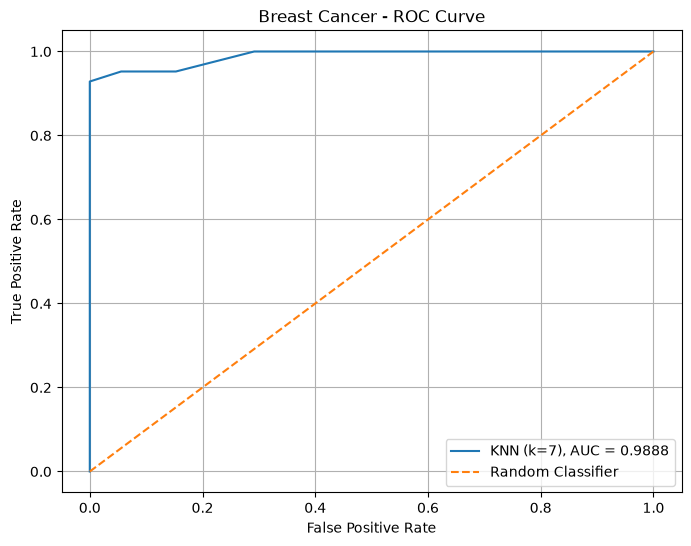

In [36]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    y_test_proba
)

roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"KNN (k=7), AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Breast Cancer - ROC Curve")
plt.legend()
plt.grid()
plt.show()

In [37]:
cancer_test = pd.DataFrame([{
    "dataset": "Breast Cancer",
    "model": "KNN_k_7",
    "representation": "scaled",
    "accuracy": test_accuracy,
    "precision_macro": test_precision,
    "recall_macro": test_recall,
    "f1_macro": test_f1,
    "roc_auc": test_roc_auc
}])

cancer_test.to_csv("bc_classifier_test.csv", index=False)

print("Test results have been saved successfully!")

Test results have been saved successfully!


## 10. K-Means Clustering – Unsupervised Learning
I applied K-Means clustering with two clusters using scaled and unscaled data. I evaluated the results using ARI and silhouette scores. The scaled model achieved a higher test ARI of 0.7354, showing better agreement with the real classes.

In [38]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

seed = 42

In [39]:

kmeans_results = []
kmeans_models = {}

for seed in seeds:

    train_idx = splits[seed]["train_idx"]
    val_idx = splits[seed]["val_idx"]

    y_val = y_series.loc[val_idx]

    representations = {
        "unscaled": (
            X_df.loc[train_idx],
            X_df.loc[val_idx]
        ),
        "scaled": (
            scaled_data[seed]["X_train_scaled"],
            scaled_data[seed]["X_val_scaled"]
        )
    }

    for representation, (X_train_rep, X_val_rep) in representations.items():

        model = KMeans(
            n_clusters=2,
            random_state=seed,
            n_init=10
        )

        model.fit(X_train_rep)

        val_clusters = model.predict(X_val_rep)

        inertia = model.inertia_

        ari = adjusted_rand_score(
            y_val,
            val_clusters
        )

        if 1 < len(set(val_clusters)) < len(val_clusters):
            silhouette = silhouette_score(
                X_val_rep,
                val_clusters
            )
        else:
            silhouette = float("nan")

        kmeans_results.append({
            "dataset": "Breast Cancer",
            "seed": seed,
            "representation": representation,
            "inertia": inertia,
            "ari": ari,
            "silhouette": silhouette
        })

        kmeans_models[(seed, representation)] = model

cancer_kmeans_runs = pd.DataFrame(kmeans_results)

from IPython.display import display

display(cancer_kmeans_runs)


,dataset,seed,representation,inertia,ari,silhouette
0,Breast Cancer,42,unscaled,5.156538e+07,0.399462,0.638725
1,Breast Cancer,42,scaled,7.918810e+03,0.451557,0.285448
2,Breast Cancer,52,unscaled,4.919078e+07,0.612245,0.697473
3,Breast Cancer,52,scaled,8.003001e+03,0.558609,0.375031
4,Breast Cancer,62,unscaled,5.305649e+07,0.501339,0.695777
5,Breast Cancer,62,scaled,7.922515e+03,0.733598,0.275781


In [40]:
cancer_kmeans_summary = (
    cancer_kmeans_runs
    .groupby(["dataset", "representation"])
    .agg(
        inertia_mean=("inertia", "mean"),
        inertia_std=("inertia", "std"),
        ari_mean=("ari", "mean"),
        ari_std=("ari", "std"),
        silhouette_mean=("silhouette", "mean"),
        silhouette_std=("silhouette", "std")
    )
    .reset_index()
)

display(cancer_kmeans_summary)

,dataset,representation,inertia_mean,inertia_std,ari_mean,ari_std,silhouette_mean,silhouette_std
0,Breast Cancer,scaled,7.948109e+03,4.757427e+01,0.581255,0.142378,0.312086,0.054725
1,Breast Cancer,unscaled,5.127088e+07,1.949607e+06,0.504349,0.106423,0.677325,0.033440


In [41]:
test_idx = splits[42]["test_idx"]
y_test = y_series.loc[test_idx]

kmeans_test_results = []

for representation in ["unscaled", "scaled"]:

    model = kmeans_models[(42, representation)]

    if representation == "unscaled":
        X_test_rep = X_df.loc[test_idx]
    else:
        X_test_rep = scaled_data[42]["X_test_scaled"]

    test_clusters = model.predict(X_test_rep)

    test_ari = adjusted_rand_score(
        y_test,
        test_clusters
    )

    if 1 < len(set(test_clusters)) < len(test_clusters):
        test_silhouette = silhouette_score(
            X_test_rep,
            test_clusters
        )
    else:
        test_silhouette = float("nan")

    kmeans_test_results.append({
        "dataset": "Breast Cancer",
        "seed": 42,
        "representation": representation,
        "ari": test_ari,
        "silhouette": test_silhouette
    })

cancer_kmeans_test = pd.DataFrame(kmeans_test_results)

display(cancer_kmeans_test)

,dataset,seed,representation,ari,silhouette
0,Breast Cancer,42,unscaled,0.558488,0.711999
1,Breast Cancer,42,scaled,0.735381,0.325062


In [42]:

for representation in ["unscaled", "scaled"]:

    model = kmeans_models[(42, representation)]

    if representation == "unscaled":
        X_test_rep = X_df.loc[test_idx]
    else:
        X_test_rep = scaled_data[42]["X_test_scaled"]

    test_clusters = model.predict(X_test_rep)

    print(f"\nRepresentation: {representation}")

    print("\nCluster Counts:")
    print(
        pd.Series(test_clusters)
        .value_counts()
        .sort_index()
    )

    contingency = pd.crosstab(
        y_test.map({0: "Malignant", 1: "Benign"}),
        pd.Series(test_clusters, index=y_test.index),
        rownames=["True Class"],
        colnames=["Predicted Cluster"]
    )

    print("\nContingency Table:")
    display(contingency)



Representation: unscaled

Cluster Counts:
0    86
1    28
Name: count, dtype: int64

Contingency Table:


Predicted Cluster,0,1
True Class,,
Benign,72,0
Malignant,14,28



Representation: scaled

Cluster Counts:
0    74
1    40
Name: count, dtype: int64

Contingency Table:


Predicted Cluster,0,1
True Class,,
Benign,69,3
Malignant,5,37


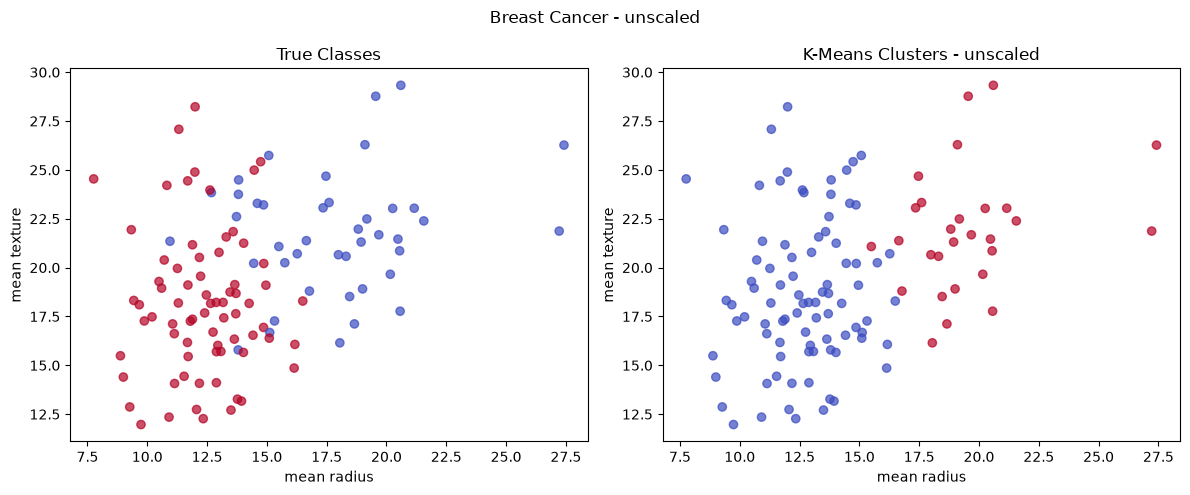

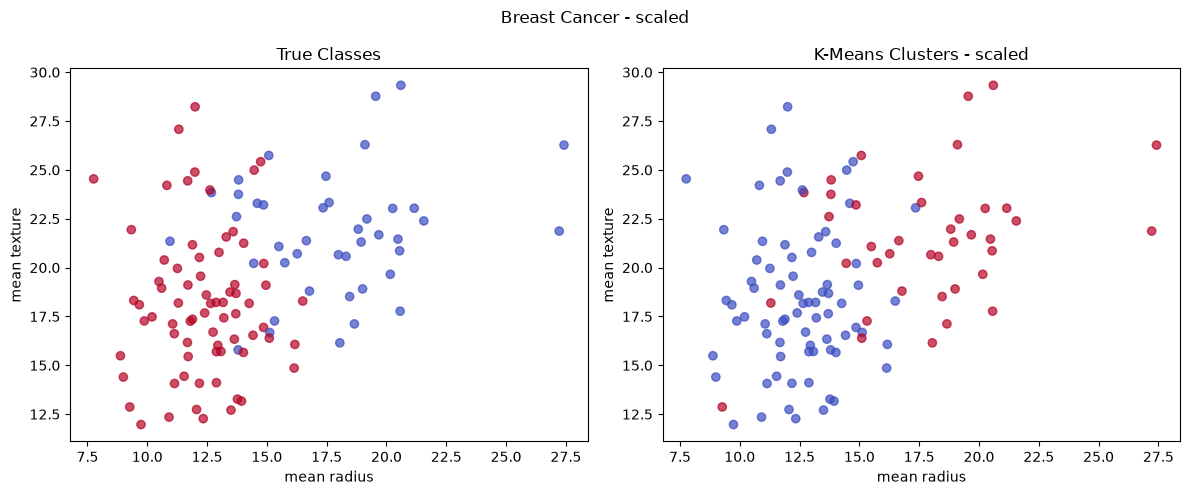

In [43]:

import matplotlib.pyplot as plt

features = ["mean radius", "mean texture"]

for representation in ["unscaled", "scaled"]:

    model = kmeans_models[(42, representation)]

    if representation == "unscaled":
        X_test_rep = X_df.loc[test_idx]
    else:
        X_test_rep = scaled_data[42]["X_test_scaled"]

    test_clusters = model.predict(X_test_rep)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].scatter(
        X_df.loc[test_idx, features[0]],
        X_df.loc[test_idx, features[1]],
        c=y_test,
        cmap="coolwarm",
        alpha=0.7
    )

    axes[0].set_title("True Classes")

    axes[1].scatter(
        X_df.loc[test_idx, features[0]],
        X_df.loc[test_idx, features[1]],
        c=test_clusters,
        cmap="coolwarm",
        alpha=0.7
    )

    axes[1].set_title(
        f"K-Means Clusters - {representation}"
    )

    for ax in axes:
        ax.set_xlabel(features[0])
        ax.set_ylabel(features[1])

    plt.suptitle(f"Breast Cancer - {representation}")
    plt.tight_layout()
    plt.show()


In [44]:
cancer_kmeans_runs.to_csv(
    "bc_kmeans_runs.csv",
    index=False
)

cancer_kmeans_summary.to_csv(
    "bc_kmeans_summary.csv",
    index=False
)

cancer_kmeans_test.to_csv(
    "bc_kmeans_test.csv",
    index=False
)

print("K-Means CSV files saved successfully!")

K-Means CSV files saved successfully!
